# 01 · Data understanding and preprocessing

Covers the *Data Understanding and Preprocessing* checkpoint:

1. Setup and loading (Colab / Kaggle / local, same code)
2. Verifying the annotation conversion (YOLO txt vs COCO json, visual check)
3. EDA: classes, object sizes, objects per frame, resolutions, ignored regions, variation across clips
4. Decisions derived from the EDA: input resolution, frame subsampling step, anchor configuration
5. Sequence-level validation protocol, saved to `splits.json` and reused by every model notebook
6. Sanity checks of the shared evaluator and the submission writer

Runs on **CPU**, no GPU needed. All figures are saved to `WORK_DIR/figures` for the report.

## 1. Setup

In [1]:
# --- Environment detection and paths ---------------------------------------------
import os, sys, glob, subprocess
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle/input")
COMPETITION = "PUT-COMPETITION-SLUG-HERE"   # Colab only: the part of the Kaggle URL after /competitions/

def find_repo():
    """Folder that contains the vdet/ package."""
    if IN_COLAB:
        return "/content/drive/MyDrive/visdrone-det"
    if IN_KAGGLE:  # code uploaded as a Kaggle dataset; its exact nesting depends on how it was uploaded
        for depth in range(1, 6):
            hits = glob.glob("/kaggle/input/" + "*/" * depth + "vdet/__init__.py")
            if hits:
                return os.path.dirname(os.path.dirname(hits[0]))
        raise FileNotFoundError("vdet not found: add the code dataset via '+ Add Input'")
    return os.path.abspath("..")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    os.environ.setdefault("VDET_WORK", "/content/drive/MyDrive/visdrone-work")  # survives disconnects
    if not os.path.exists("/content/data/train"):
        # Needs kaggle.json (Kaggle -> Settings -> Create New Token) saved in MyDrive root
        !mkdir -p /root/.kaggle && cp /content/drive/MyDrive/kaggle.json /root/.kaggle/ && chmod 600 /root/.kaggle/kaggle.json
        !kaggle competitions download -c {COMPETITION} -p /content -q
        !unzip -q -o /content/{COMPETITION}.zip -d /content/data && rm /content/{COMPETITION}.zip

try:
    import pycocotools
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycocotools"], check=True)

REPO_DIR = find_repo()
sys.path.insert(0, REPO_DIR)
print("repo:", REPO_DIR)

repo: /kaggle/input/datasets/maksymholovin/visdrone-det-code/visdrone-det


In [2]:
# --- Imports and global config ------------------------------------------------------
import json, random
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

from vdet import CLASSES
from vdet import data as D, evaluate as E, submission as S, anchors as A, viz as V
from vdet.paths import find_data_root, default_work_dir

SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 160, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

DATA_ROOT = find_data_root()
WORK_DIR = default_work_dir()
FIG_DIR = WORK_DIR / "figures"; FIG_DIR.mkdir(exist_ok=True)

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

print("data:", DATA_ROOT, "\nwork:", WORK_DIR)

data: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026 
work: /kaggle/working


In [3]:
# --- Load train + val annotations (COCO json is the single source of truth) --------
tv = D.load_train_val(DATA_ROOT)
test = D.load_test_images(DATA_ROOT)
im, bx, ig = tv.images, tv.boxes.merge(tv.images[["key", "split", "clip"]], on="key"), tv.ignore
bx["side"] = np.sqrt(bx.area)          # geometric mean of w and h, the usual "object size"
print(tv)

summary = pd.DataFrame({
    "clips": im.groupby("split")["clip"].nunique(),
    "frames": im.groupby("split").size(),
    "objects": bx.groupby("split").size(),
    "ignore_regions": ig.merge(im[["key", "split"]]).groupby("split").size(),
})
summary.loc["test"] = [test["clip"].nunique(), len(test), np.nan, np.nan]
summary["objects/frame"] = (summary.objects / summary.frames).round(1)
summary

SplitData(images=27047, boxes=1219648, ignore=67838, clips=63)


,clips,frames,objects,ignore_regions,objects/frame
split,,,,,
train,56.0,24201.0,1105516.0,63843.0,45.7
val,7.0,2846.0,114132.0,3995.0,40.1
test,48.0,3811.0,NaN,NaN,NaN


## 2. Verifying the conversion

The data comes in two formats. We load everything from the COCO json and check it against the
YOLO txt files on random frames. Agreement within rounding (< 1 px) means both describe the same boxes.

In [4]:
chk = pd.concat([D.verify_yolo_vs_coco(tv, DATA_ROOT, s, n=300) for s in ("train", "val")])
print("frames checked:", len(chk))
print("object count mismatches:", (chk.yolo_objs != chk.coco_objs).sum())
print("ignore-region count mismatches:", (chk.yolo_ignore != chk.coco_ignore).sum())
print("max coordinate disagreement (px):", round(chk.max_px_err.max(), 3))

frames checked: 600
object count mismatches: 0
ignore-region count mismatches: 0
max coordinate disagreement (px): 0.003


In [5]:
# Ignore regions: the YOLO ignore/*.txt files and the COCO iscrowd annotations do not always agree.
# Which source has more regions, are the YOLO regions contained in COCO, and what are the extra ones?
mm = chk[chk.yolo_ignore != chk.coco_ignore]
print(f"frames with a different number of ignore regions: {len(mm)} of {len(chk)}")
print(f"  COCO has more: {(mm.coco_ignore > mm.yolo_ignore).sum()},  YOLO has more: {(mm.yolo_ignore > mm.coco_ignore).sum()}")
print(f"total regions  YOLO: {chk.yolo_ignore.sum()}   COCO: {chk.coco_ignore.sum()}")
print(f"YOLO regions also present in COCO: {chk.yolo_ign_in_coco.sum() / max(chk.yolo_ignore.sum(), 1) * 100:.1f}%")
print(f"COCO regions also present in YOLO: {chk.coco_ign_in_yolo.sum() / max(chk.coco_ignore.sum(), 1) * 100:.1f}%")
print(f"exact duplicate regions inside COCO: {chk.coco_ign_duplicates.sum()}")
print("orig_category_id of COCO-only regions:", pd.Series(sum(chk.coco_only_orig_cats, [])).value_counts().to_dict())
print("orig_category_id of all COCO ignore regions:", ig["orig_category_id"].value_counts().to_dict() if "orig_category_id" in ig else "n/a")
mm.head()

frames with a different number of ignore regions: 0 of 600
  COCO has more: 0,  YOLO has more: 0
total regions  YOLO: 1238   COCO: 1238
YOLO regions also present in COCO: 100.0%
COCO regions also present in YOLO: 100.0%
exact duplicate regions inside COCO: 0
orig_category_id of COCO-only regions: {}
orig_category_id of all COCO ignore regions: {0: 66363, 11: 1475}


,key,yolo_objs,coco_objs,yolo_ignore,coco_ignore,yolo_ign_in_coco,coco_ign_in_yolo,coco_ign_duplicates,coco_only_orig_cats,max_px_err


In [6]:
# Original VisDrone classes -> the 8 competition classes (shows which classes were merged)
if "orig_category_id" in bx:
    display(pd.crosstab(bx.orig_category_id, bx.cat.map(dict(enumerate(CLASSES)))))

cat,bicycle,bus,car,motor,person,tricycle,truck,van
orig_category_id,,,,,,,,
1,0,0,0,0,266709,0,0,0
2,0,0,0,0,112304,0,0,0
3,46277,0,0,0,0,0,0,0
4,0,0,537122,0,0,0,0,0
5,0,0,0,0,0,0,0,53782
6,0,0,0,0,0,0,31857,0
7,0,0,0,0,0,32107,0,0
8,0,0,0,0,0,14729,0,0
9,0,9917,0,0,0,0,0,0


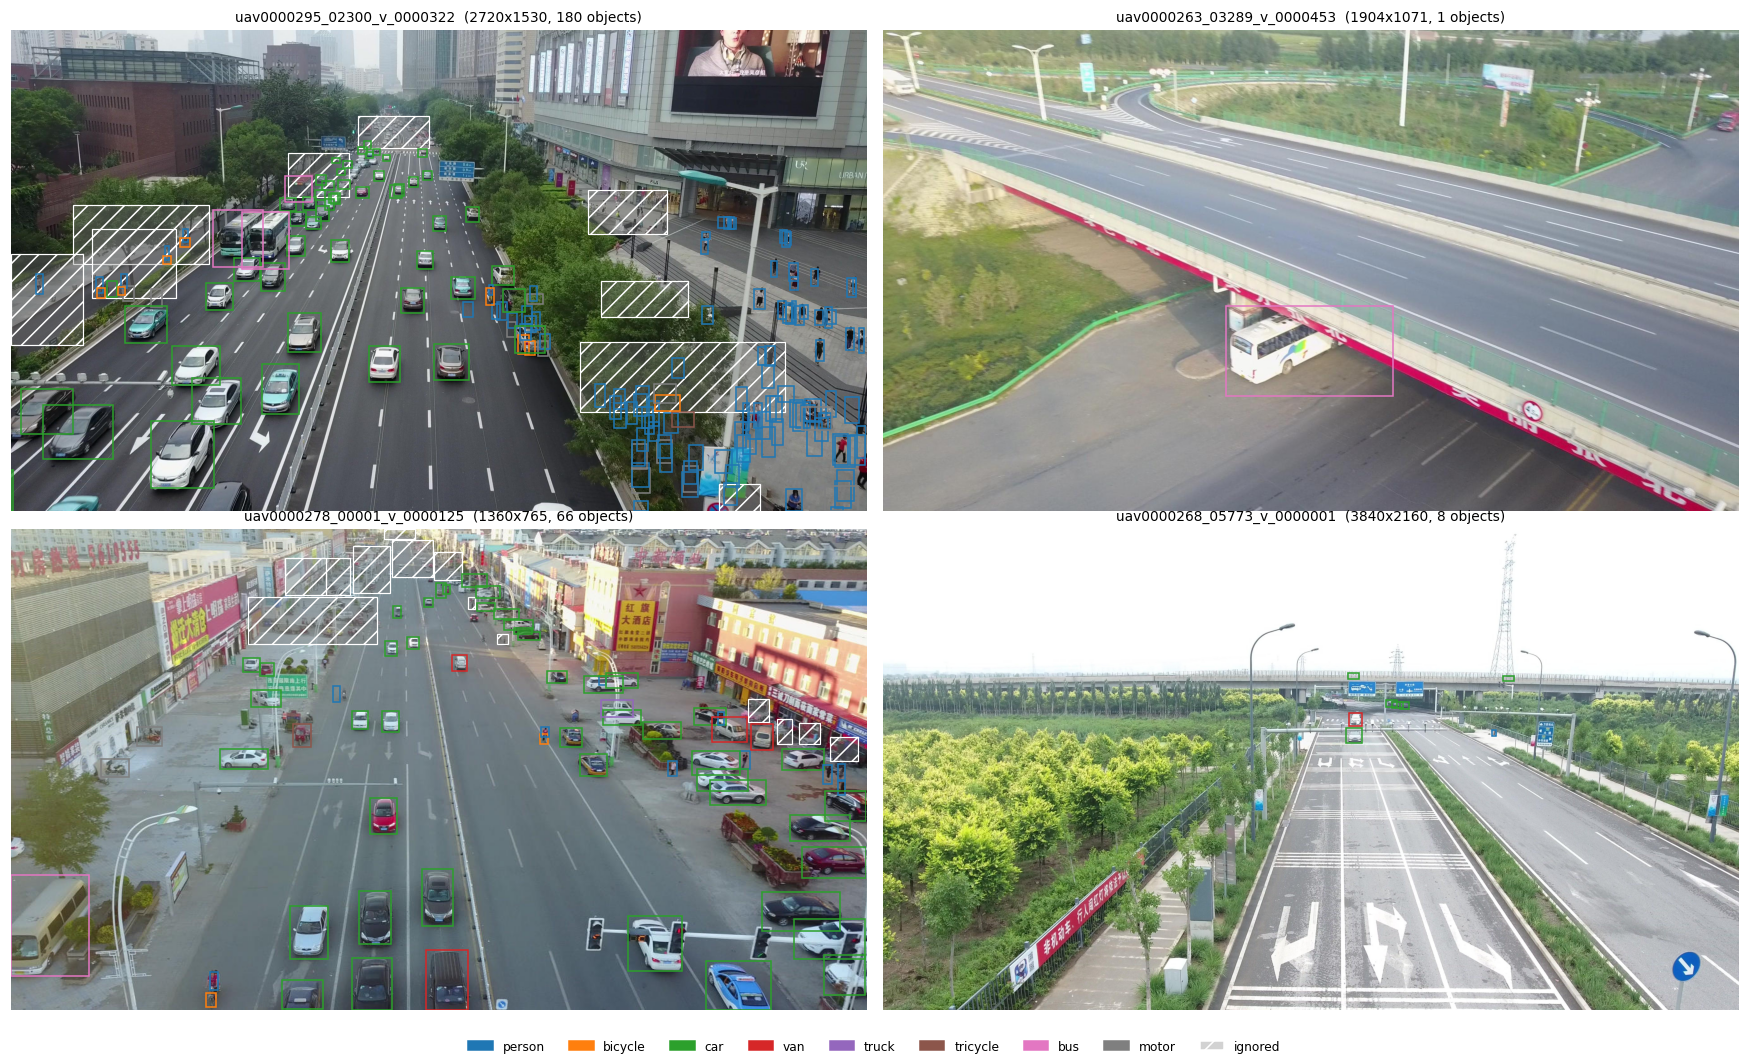

In [7]:
# Visual check: densest frame, sparsest frame, a frame with ignored regions, the highest resolution
per_frame = bx.groupby("key").size().reindex(im.key, fill_value=0)
keys = [per_frame.idxmax(), per_frame[per_frame > 0].idxmin(),
        ig.key.iloc[len(ig) // 2] if len(ig) else per_frame.index[0],
        im.loc[(im.width * im.height).idxmax(), "key"]]
fig = V.show_frames(tv, keys, cols=2, size=8)
savefig(fig, "gt_examples"); plt.show()

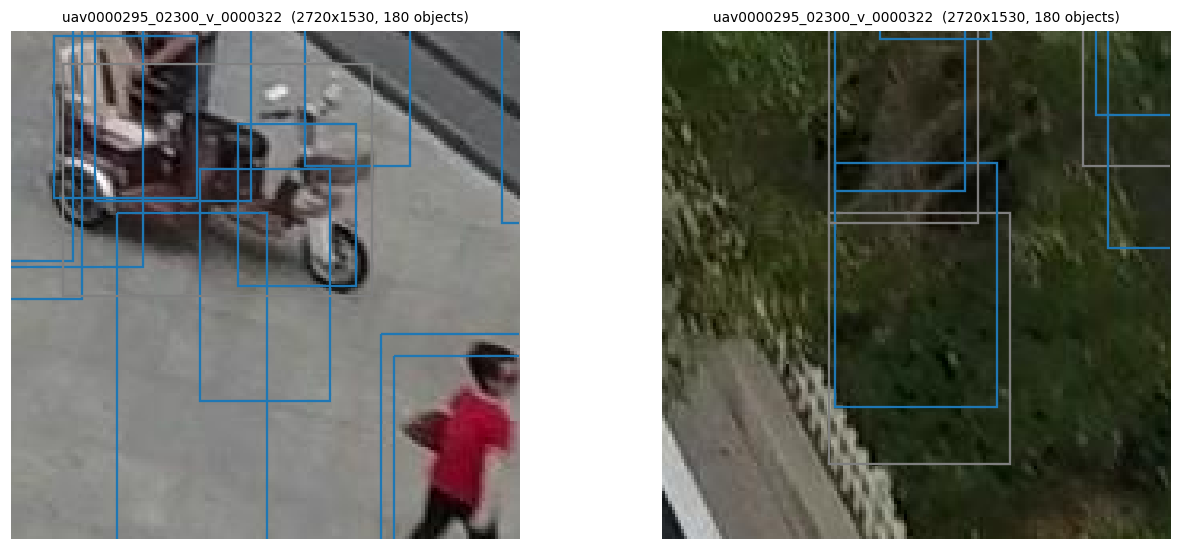

In [8]:
# Zoom into the densest frame: are boxes tight around tiny objects?
k = keys[0]; b = tv.boxes[tv.boxes.key == k]
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, (_, r) in zip(ax, b.sample(2, random_state=SEED).iterrows()):
    V.show_crop(a, tv, k, r.x + r.w / 2, r.y + r.h / 2, half=80, lw=1.5)
savefig(fig, "gt_zoom"); plt.show()

> **Observation.** COCO json and YOLO txt agree on all 600 checked frames: the same object and ignore-region counts and at most
> 0.003 px difference in coordinates. The raw COCO json repeats every ignore region once per class; `data.py` removes
> these copies, so the COCO json alone can be used as the source of truth. The original VisDrone classes were merged:
> pedestrian + people → person, tricycle + awning-tricycle → tricycle; the original category "others" is ignored
> together with the ignored regions. The zoomed densest frame shows tight boxes even around objects of a few pixels.

## 3. Exploratory analysis
### 3.1 Class distribution

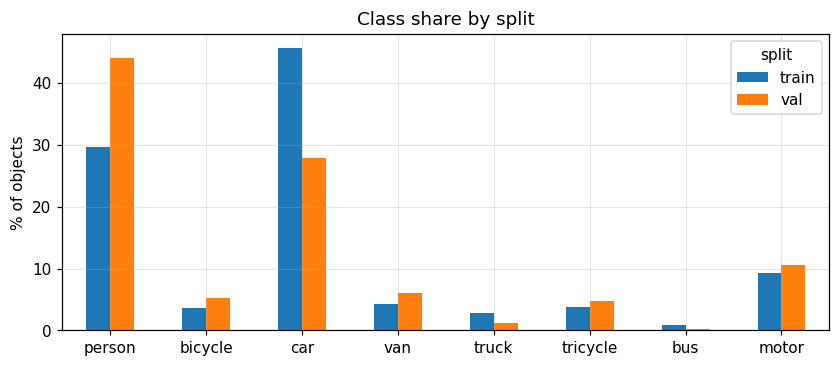

split,train,val,train_pct,val_pct
person,328701,50312,29.7,44.1
bicycle,40255,6022,3.6,5.3
car,505301,31821,45.7,27.9
van,46940,6842,4.2,6.0
truck,30498,1359,2.8,1.2
tricycle,41349,5487,3.7,4.8
bus,9653,264,0.9,0.2
motor,102819,12025,9.3,10.5


In [9]:
cnt = bx.groupby(["split", "cat"]).size().unstack(0).fillna(0)
cnt.index = CLASSES
share = (cnt / cnt.sum() * 100).round(1)
fig, ax = plt.subplots(figsize=(9, 3.5))
share.plot.bar(ax=ax, rot=0); ax.set_ylabel("% of objects"); ax.set_title("Class share by split")
savefig(fig, "class_share"); plt.show()
display(cnt.astype(int).assign(train_pct=share["train"], val_pct=share["val"]))

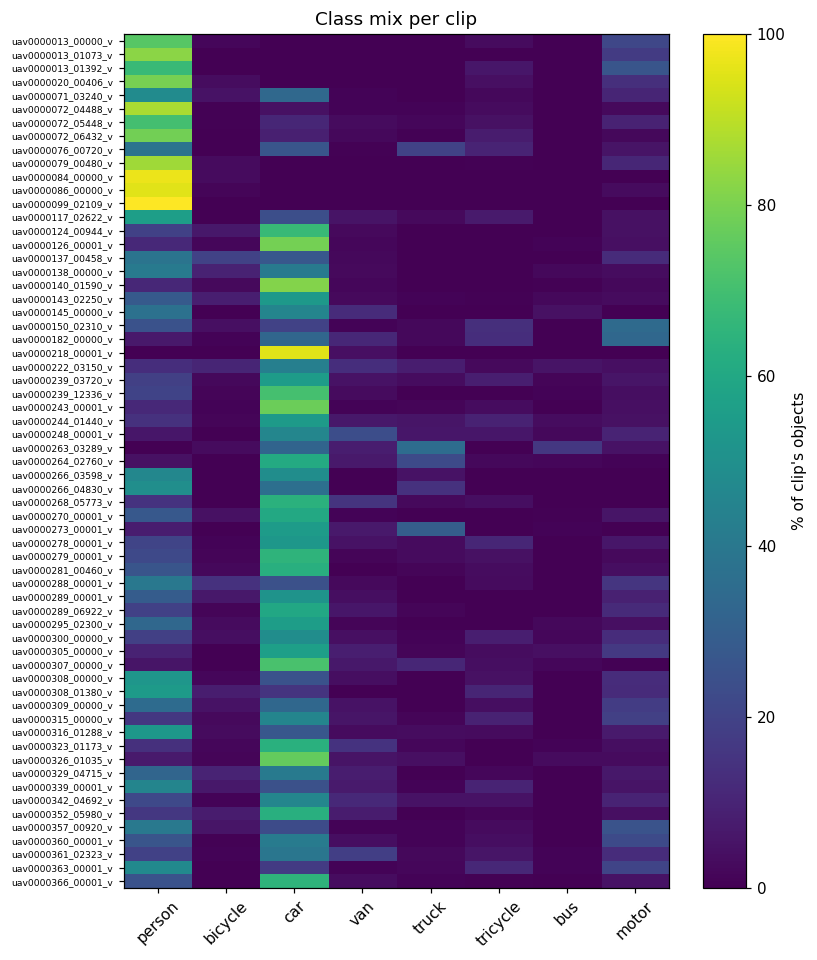

clips where a class is absent:
 person       1
bicycle     17
car          8
van         11
truck       19
tricycle    19
bus         38
motor        7
dtype: int64


In [10]:
# How much does the class mix change from clip to clip? (rows = clips, % of objects)
by_clip = pd.crosstab(bx["clip"], bx.cat, normalize="index").reindex(columns=range(len(CLASSES)), fill_value=0) * 100
by_clip.columns = CLASSES
fig, ax = plt.subplots(figsize=(8, max(4, len(by_clip) * 0.16)))
im_ = ax.imshow(by_clip.values, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45); ax.set_yticks(range(len(by_clip)), by_clip.index, fontsize=6)
ax.grid(False); plt.colorbar(im_, label="% of clip's objects"); ax.set_title("Class mix per clip")
savefig(fig, "class_mix_per_clip"); plt.show()
print("clips where a class is absent:\n", (by_clip == 0).sum())

> **Observation.** The classes are very imbalanced: car is 45.7% and person 29.7% of training objects, bus only 0.9%.
> The official val set has a different mix (person 44.1%, car 27.9%, bus 0.2% = 264 objects), and the mix changes from
> clip to clip: bus is absent from 38 of 63 clips, truck and tricycle from 19. COCO mAP averages the 8 classes equally,
> so a rare class weighs as much as car, and per-class AP of bus and truck on val is noisy. We report per-class AP
> and do not tune anything for single rare classes.

### 3.2 Object sizes

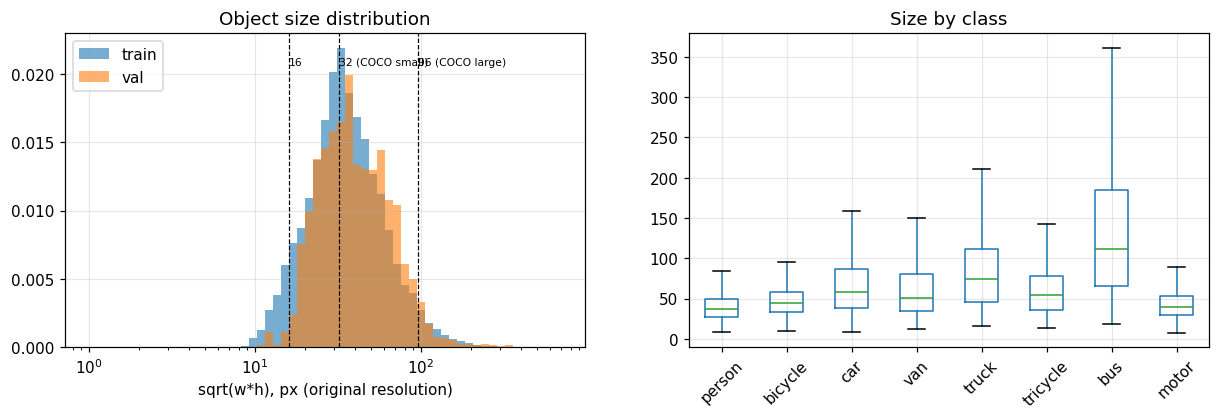

side,<16 (tiny),16-32,32-96,>96
split,,,,
train,2.2,22.8,63.5,11.6
val,0.4,18.8,69.5,11.3


In [11]:
bins = np.logspace(0, np.log10(bx.side.max() + 1), 60)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for s, g in bx.groupby("split"):
    ax[0].hist(g.side, bins=bins, alpha=0.6, density=True, label=s)
for t, lab in [(16, "16"), (32, "32 (COCO small)"), (96, "96 (COCO large)")]:
    ax[0].axvline(t, ls="--", c="k", lw=0.8); ax[0].text(t, ax[0].get_ylim()[1] * 0.9, lab, fontsize=7)
ax[0].set_xscale("log"); ax[0].set_xlabel("sqrt(w*h), px (original resolution)"); ax[0].legend()
ax[0].set_title("Object size distribution")
bx.boxplot("side", by="cat", ax=ax[1], showfliers=False)
ax[1].set_xticklabels(CLASSES, rotation=45); ax[1].set_title("Size by class"); ax[1].set_xlabel("")
fig.suptitle(""); savefig(fig, "object_sizes"); plt.show()

size_bucket = pd.cut(bx.side, [0, 16, 32, 96, 1e9], labels=["<16 (tiny)", "16-32", "32-96", ">96"])
pd.crosstab(bx.split, size_bucket, normalize="index").mul(100).round(1)

In [12]:
# Aspect ratio (h/w) by class: informs anchor aspect ratios
bx["ar"] = bx.h / bx.w
display(bx.groupby(bx.cat.map(dict(enumerate(CLASSES))))["ar"].describe(percentiles=[.1, .5, .9]).round(2))

,count,mean,std,min,10%,50%,90%,max
cat,,,,,,,,
bicycle,46277.0,1.19,0.58,0.09,0.58,1.08,1.95,7.55
bus,9917.0,0.96,0.55,0.07,0.34,0.96,1.62,11.12
car,537122.0,0.81,0.36,0.04,0.41,0.79,1.22,18.57
motor,114844.0,1.27,0.55,0.05,0.65,1.24,1.97,17.80
person,379013.0,2.01,0.58,0.06,1.31,2.00,2.72,20.00
tricycle,46836.0,1.00,0.38,0.13,0.55,0.95,1.52,4.05
truck,31857.0,0.90,0.55,0.11,0.43,0.93,1.29,38.75
van,53782.0,0.92,0.38,0.09,0.51,0.88,1.41,17.22


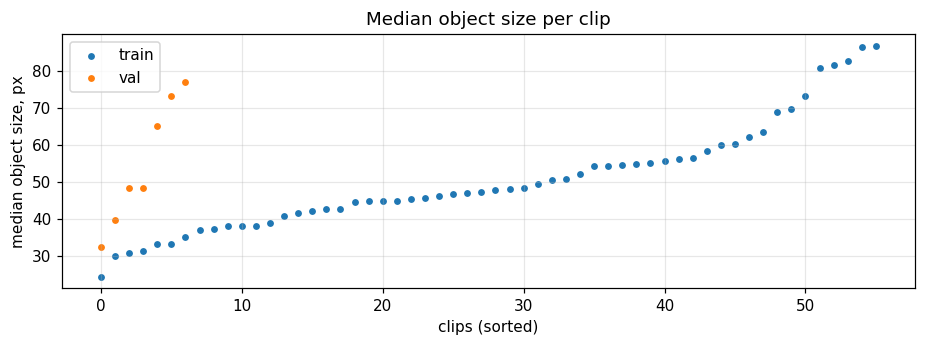

In [13]:
# Size depends strongly on the clip (flight altitude): median object size per clip
med = bx.groupby(["split", "clip"]).side.median().reset_index()
fig, ax = plt.subplots(figsize=(10, 3))
for s, g in med.groupby("split"):
    ax.scatter(range(len(g)), g.side.sort_values(), s=12, label=s)
ax.set_ylabel("median object size, px"); ax.set_xlabel("clips (sorted)"); ax.legend(); ax.set_title("Median object size per clip")
savefig(fig, "size_per_clip"); plt.show()

> **Observation.** Objects are small: at original resolution 25% of training objects are below 32 px (2.2% below 16 px).
> Val has fewer tiny objects (0.4%) than train. Object size depends mainly on the clip (flight altitude) rather than on
> the class. Shapes differ by class: person is tall (median h/w 2.0), car is wide (0.79), so anchors need aspect
> ratios from about 0.5 to 2.

### 3.3 Objects per frame (scene density)

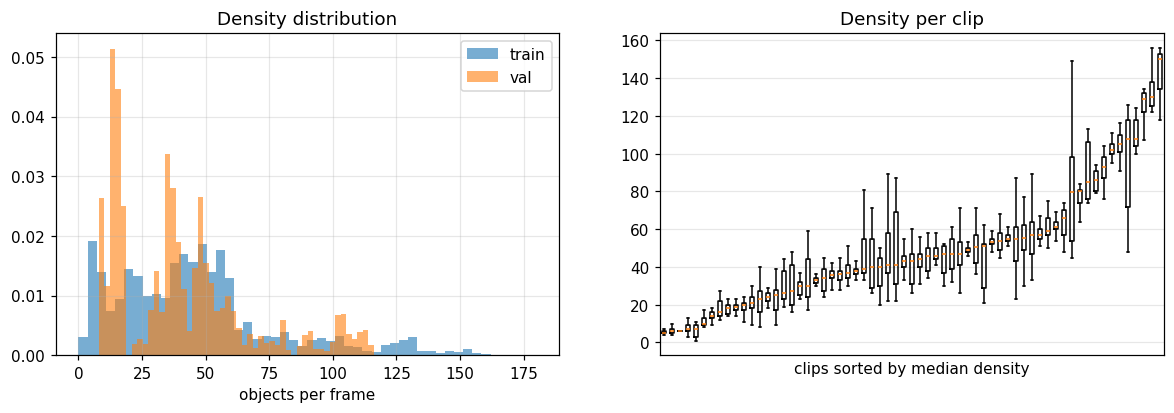

,count,mean,std,min,50%,90%,99%,max
split,,,,,,,,
train,24201.0,45.7,31.6,0.0,43.0,92.0,142.0,180.0
val,2846.0,40.1,26.8,8.0,37.0,81.0,112.6,116.0


In [14]:
pf = per_frame.rename("n").reset_index().merge(im[["key", "split", "clip"]])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for s, g in pf.groupby("split"):
    ax[0].hist(g.n, bins=50, alpha=0.6, density=True, label=s)
ax[0].set_xlabel("objects per frame"); ax[0].legend(); ax[0].set_title("Density distribution")
order = pf.groupby("clip").n.median().sort_values().index
ax[1].boxplot([pf[pf["clip"] == c].n for c in order], showfliers=False)
ax[1].set_xticks([]); ax[1].set_xlabel("clips sorted by median density"); ax[1].set_title("Density per clip")
savefig(fig, "objects_per_frame"); plt.show()
pf.groupby("split").n.describe(percentiles=[.5, .9, .99]).round(1)

In [15]:
# Relevant limits: DETR-style models use a fixed number of queries (RT-DETR default 300),
# the leaderboard scores at most 500 detections per image.
for lim in (100, 300, 500):
    print(f"frames with > {lim} objects: {(pf.n > lim).mean() * 100:.2f}%   (max = {pf.n.max()})")

frames with > 100 objects: 7.52%   (max = 180)
frames with > 300 objects: 0.00%   (max = 180)
frames with > 500 objects: 0.00%   (max = 180)


> **Observation.** A training frame has 45.7 objects on average, 92 at the 90th percentile and up to 180; 7.5% of frames have more
> than 100 objects. No frame exceeds 300 objects, so RT-DETR's 300 queries are enough in number, but dense frames use
> a large share of them. Faster R-CNN's default limit of 100 detections per image would cut recall in these frames,
> so all models keep up to 500 detections (the leaderboard limit).

### 3.4 Image resolution, occlusion, ignored regions

In [16]:
# Number of clips per resolution in each split: is the test set at the same resolutions as train?
res = pd.concat([im, test], ignore_index=True).drop_duplicates("clip")
res["resolution"] = res.width.astype(int).astype(str) + "x" + res.height.astype(int).astype(str)
pd.crosstab(res["resolution"], res["split"])

split,test,train,val
resolution,,,
1344x756,7,11,2
1360x764,18,0,0
1360x765,0,1,0
1904x1071,0,30,2
1904x1072,4,0,0
1920x1080,11,1,0
2688x1512,0,11,1
2720x1530,0,2,1
3840x2160,0,0,1


In [17]:
if "occlusion" in bx:
    display(pd.crosstab(bx.cat.map(dict(enumerate(CLASSES))), bx.occlusion, normalize="index").mul(100).round(1)
            .rename(columns=lambda c: f"occl={c}"))
if "truncation" in bx:
    print("truncated objects: %.1f%%" % ((bx.truncation > 0).mean() * 100))

occlusion,occl=0.0,occl=1.0,occl=2.0
cat,,,
bicycle,41.7,55.1,3.2
bus,56.6,41.3,2.0
car,56.2,38.9,4.9
motor,51.9,41.7,6.4
person,53.0,40.9,6.1
tricycle,41.7,55.6,2.6
truck,34.6,49.8,15.6
van,54.9,41.5,3.5


truncated objects: 4.4%


In [18]:
# Ignored regions: how common are they and how much of the frame do they cover?
ig_area = ig.assign(a=ig.w * ig.h).groupby("key").a.sum()
cover = (ig_area / (im.set_index("key").width * im.set_index("key").height)).reindex(im.key).fillna(0)
print(f"frames with >= 1 ignored region: {(cover > 0).mean() * 100:.1f}%")
print(f"share of frame area ignored (frames that have them): median {cover[cover > 0].median() * 100:.1f}%, "
      f"p90 {cover[cover > 0].quantile(.9) * 100:.1f}%")
fr = D.overlap_fraction  # how many GT boxes overlap ignore regions? (decides the masking drop rule)
ig_by_key = {k: g[["x", "y", "w", "h"]].to_numpy() for k, g in ig.groupby("key")}
ov = np.concatenate([fr(g[["x", "y", "w", "h"]].to_numpy(), ig_by_key[k])
                     for k, g in tv.boxes[tv.boxes.key.isin(ig_by_key)].groupby("key")]) if len(ig) else np.zeros(0)
print(f"GT boxes in frames with ignore regions: {len(ov)}; >0% inside: {(ov > 0).mean() * 100:.1f}%, "
      f">50% inside: {(ov > 0.5).mean() * 100:.1f}%")

frames with >= 1 ignored region: 72.2%
share of frame area ignored (frames that have them): median 1.6%, p90 8.2%
GT boxes in frames with ignore regions: 966202; >0% inside: 4.4%, >50% inside: 1.3%


> **Observation.** Resolutions range from 1344×756 to 3840×2160. 1360×764, 960×540 and 680×382 appear only in test, so test objects
> may be smaller in pixels (a hypothesis; we only know test image sizes, not labels). About 41% of objects are partly
> occluded; trucks are heavily occluded most often (15.6%). 72% of frames contain an ignored region, but it covers
> only 1.6% of the frame (median) and only 1.3% of boxes lie more than half inside one. Decision: in training images
> ignored regions are filled with the mean colour and boxes more than 50% inside are dropped; in evaluation they are
> crowd regions for every class, so detections there are not penalised.

## 4. Decisions derived from the EDA
### 4.1 Input resolution
Detectors resize every frame. The table shows what fraction of objects becomes smaller than
8 / 16 / 32 px after resizing the longer side to a given size. Objects below ~8 px at the
stride-8 level (P3) occupy a single feature cell and are very hard to detect.

In [19]:
rows = []
for L in (640, 960, 1280, 1536, "orig"):
    wh = bx[["w", "h"]].to_numpy() if L == "orig" else A.scale_to_input(tv.boxes, im, L)
    side = np.sqrt(wh.prod(1))
    rows.append({"long side": L, "<8px %": (side < 8).mean() * 100, "<16px %": (side < 16).mean() * 100,
                 "<32px %": (side < 32).mean() * 100, "median px": np.median(side)})
pd.DataFrame(rows).set_index("long side").round(1)

,<8px %,<16px %,<32px %,median px
long side,,,,
640,9.7,53.6,89.2,15.3
960,1.8,23.5,73.2,22.9
1280,0.6,9.7,53.6,30.6
1536,0.2,4.8,39.4,36.7
orig,0.0,2.0,24.4,46.4


> **Observation.** At 640 px (long side) 53.6% of objects become smaller than 16 px; at 1280 px only 9.7% (median side 30.6 px).
> 1536 px would reduce this to 4.8%, but does not fit the memory and time of a T4 for 25 epochs. Decision: train and
> predict at 1280 px. Notebook 02 confirms it: YOLO 640 → 1280 px gives +7.4 mAP.

### 4.2 Frame subsampling step
Consecutive frames are almost identical. For every tracked object we compare its box at frame *t*
with frame *t+gap*. When the median IoU is high, the two frames carry nearly the same supervision,
so training on both costs GPU time without adding information.

,gap,pairs,median_iou,frac_iou_gt_0_7
0,1,1210912,0.895,0.854
1,2,1202547,0.806,0.664
2,3,1194217,0.727,0.534
3,5,1177672,0.591,0.391
4,10,1137275,0.348,0.252
5,20,1060628,0.093,0.172
6,50,859089,0.000,0.116


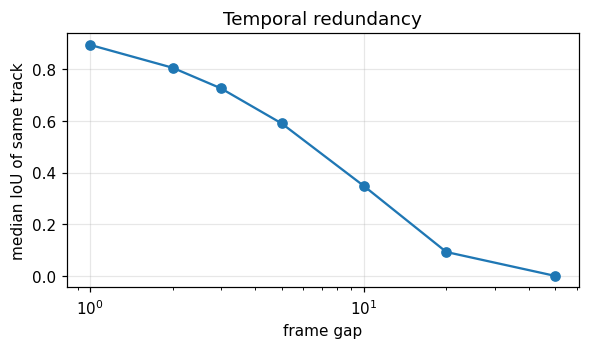

In [20]:
tg = D.track_iou_vs_gap(tv, gaps=(1, 2, 3, 5, 10, 20, 50))
display(tg.round(3))
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(tg.gap, tg.median_iou, "o-"); ax.set_xscale("log"); ax.set_xlabel("frame gap"); ax.set_ylabel("median IoU of same track")
ax.set_title("Temporal redundancy"); savefig(fig, "temporal_redundancy"); plt.show()

In [21]:
# Choose the step after reading the table above (the default 5 gives ~1/5 of the frames).
TRAIN_STEP = 5   # training frames: every 5th frame of each clip
VAL_STEP = 1     # validation: all frames (final numbers). Use 3 for faster per-epoch monitoring.
n_tr = len(D.subsample_frames(im[im.split == "train"], TRAIN_STEP))
print(f"train frames after subsampling: {n_tr} of {(im.split == 'train').sum()}")

train frames after subsampling: 4868 of 24201


> **Observation.** The same object overlaps its own box with median IoU 0.895 in the next frame, 0.591 five frames later and
> 0.348 ten frames later. Neighbouring frames are near-duplicates, so training on all of them costs GPU time without
> new information. With step 5 the boxes have moved enough to add new supervision, and an epoch has 4 868 instead of
> 24 201 frames (5× cheaper). Step 10 would leave too few examples of the rare classes.

### 4.3 Anchor configuration (for the anchor-based detectors)
Under IoU-based assignment (RetinaNet: positive if IoU >= 0.5), a box whose shape matches no anchor
well enough never becomes a positive. We measure that *coverage* for torchvision's default RetinaNet
anchors and for anchors from YOLOv2-style k-means (distance 1 - IoU) at the training resolution.

In [22]:
TRAIN_LONG_SIDE = 1280   # set from 4.1
wh = A.scale_to_input(tv.boxes[tv.boxes.key.isin(im[im.split == "train"].key)], im, TRAIN_LONG_SIDE)

default = A.anchor_grid(A.TORCHVISION_RETINA_SIZES, A.DEFAULT_RATIOS, A.OCTAVE_SCALES)
km9, km9_iou = A.kmeans_anchors(wh, k=9, seed=SEED)
# candidate: same structure as torchvision (5 levels x 3 scales x 3 ratios) but smaller base sizes
small = A.anchor_grid((8, 16, 32, 64, 128), A.DEFAULT_RATIOS, A.OCTAVE_SCALES)

cov = pd.DataFrame({
    "torchvision default (32..512)": A.anchor_coverage(wh, default),
    "base sizes 8..128": A.anchor_coverage(wh, small),
    "k-means k=9": A.anchor_coverage(wh, km9),
}).T.mul(100).round(1)
display(cov)
print("k-means anchors (w, h) at", TRAIN_LONG_SIDE, "px:\n", km9.round(1))
print("k-means anchor aspect ratios h/w:", (km9[:, 1] / km9[:, 0]).round(2))

,coverage,mean_best_iou,coverage_<16px,coverage_16-32px,coverage_32-96px,coverage_>96px
torchvision default (32..512),71.9,64.8,0.0,58.9,99.9,99.7
base sizes 8..128,99.9,82.8,99.4,99.9,99.9,99.6
k-means k=9,96.2,72.6,83.2,98.6,99.0,64.0


k-means anchors (w, h) at 1280 px:
 [[ 11.4  15.5]
 [ 14.1  27.3]
 [ 26.2  20.2]
 [ 20.2  35.6]
 [ 43.   27.6]
 [ 31.6  47.6]
 [ 75.3  39.5]
 [ 53.8  66.7]
 [117.   79.3]]
k-means anchor aspect ratios h/w: [1.35 1.93 0.77 1.77 0.64 1.51 0.52 1.24 0.68]


> **Observation.** torchvision's default anchors (32–512 px) cover 0% of objects below 16 px and 58.9% of 16–32 px objects; base
> sizes 8–128 px cover 99.9% and k-means anchors 96.2%. This motivated the smaller anchors in Faster R-CNN F1 and
> RetinaNet N1. Later lesson (notebook 04, §5): this coverage only compares shapes, as if each anchor were centred on
> its object. On the real stride-8 grid a small anchor rarely reaches IoU 0.5, and N1 lost 6.6 mAP.

## 5. Validation protocol (sequence-level)
* **Primary protocol:** train on the official `train` clips, evaluate on the official `val` clips (7 whole videos).
  Every model notebook uses exactly this, with the same evaluator and the same `VAL_STEP`.
* **5-fold GroupKFold over all 63 clips** (groups = clip) is also saved. Re-training every detector 5 times does not fit
  the GPU budget (~60 h), so it is used only to check the stability of the final pipeline on extra folds.
* No clip appears in both the training and validation parts of any split, so near-duplicate frames cannot leak.

In [23]:
folds = D.make_clip_folds(im, n_splits=5)
train_clips = sorted(im[im.split == "train"]["clip"].unique())
val_clips = sorted(im[im.split == "val"]["clip"].unique())
assert not set(train_clips) & set(val_clips)

splits = {
    "seed": SEED, "train_step": TRAIN_STEP, "val_step": VAL_STEP, "train_long_side": TRAIN_LONG_SIDE,
    "train_clips": train_clips, "val_clips": val_clips,
    "folds": dict(zip(folds["clip"], folds["fold"].astype(int))),
}
(WORK_DIR / "splits.json").write_text(json.dumps(splits, indent=1))
print("saved", WORK_DIR / "splits.json")
display(folds.merge(im.groupby("clip").size().rename("frames").reset_index()).groupby("fold")
        .agg(clips=("clip", "count"), frames=("frames", "sum")))

saved /kaggle/working/splits.json


,clips,frames
fold,,
0,12,5399
1,13,5446
2,12,5370
3,13,5419
4,13,5413


In [24]:
# Is the official val representative of train? Compare the key statistics side by side.
cmp = pd.DataFrame({s: {
    "objects/frame (median)": pf[pf.split == s].n.median(),
    "object size px (median)": bx[bx.split == s].side.median(),
    "% tiny (<16px)": (bx[bx.split == s].side < 16).mean() * 100,
    "% person": (bx[bx.split == s].cat == 0).mean() * 100,
    "% car": (bx[bx.split == s].cat == 2).mean() * 100,
} for s in ("train", "val")}).round(1)
cmp

,train,val
objects/frame (median),43.0,37.0
object size px (median),45.8,52.4
% tiny (<16px),2.2,0.3
% person,29.7,44.1
% car,45.7,27.9


> **Observation.** No clip is in both train and val, so near-duplicate frames cannot leak. The official val differs from train
> (more persons, fewer cars, almost no tiny objects, median 37 vs 43 objects per frame), so absolute numbers may not
> transfer to the test set; we compare models only against each other under the same protocol. The 5 folds are saved
> but not used for training, because retraining every detector 5 times does not fit the GPU budget.

## 6. Sanity checks of the shared tools
Before any GPU time is spent: the evaluator must give **mAP = 1** for ground truth used as
predictions, lower values for jittered boxes, and must not penalise detections inside ignored regions.

In [25]:
val = tv.subset(D.subsample_frames(im[im.split == "val"], VAL_STEP).key)
ev = E.DetectionEvaluator(val)
checks = {
    "GT as predictions": ev.evaluate(E.gt_as_predictions(val)),
    "GT + 1px jitter": ev.evaluate(E.gt_as_predictions(val, 1.0)),
    "GT + 3px jitter": ev.evaluate(E.gt_as_predictions(val, 3.0)),
}
if len(val.ignore):  # one extra false detection placed inside an ignored region
    r = val.ignore.iloc[0]
    fp = pd.DataFrame([dict(key=r.key, cat=0, score=1.0, x=r.x + 1, y=r.y + 1, w=min(10, r.w - 2), h=min(10, r.h - 2))])
    checks["GT + FP inside ignore"] = ev.evaluate(pd.concat([E.gt_as_predictions(val), fp]))
E.results_table(checks)

,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR500
GT as predictions,100.0,100.0,100.0,100.0,100.0,100.0,100.0,1.000000
GT + 1px jitter,89.8,99.9,98.6,65.6,76.6,90.0,98.5,0.931494
GT + 3px jitter,65.0,97.4,72.1,25.9,35.3,64.4,85.8,0.736213
GT + FP inside ignore,100.0,100.0,100.0,100.0,100.0,100.0,100.0,1.000000


In [26]:
# Jitter of a few pixels hurts tiny objects far more than large ones: IoU is very sensitive for small boxes.
# (Motivation for size-aware losses / metrics such as NWD later.)
E.results_table(checks)[["AP_tiny", "AP_small", "AP_medium", "AP_large"]]

,AP_tiny,AP_small,AP_medium,AP_large
GT as predictions,100.0,100.0,100.0,100.0
GT + 1px jitter,65.6,76.6,90.0,98.5
GT + 3px jitter,25.9,35.3,64.4,85.8
GT + FP inside ignore,100.0,100.0,100.0,100.0


In [27]:
# The submission writer round-trips and validates the format (empty predictions -> score 0 on the LB)
empty = pd.DataFrame(columns=["key", "cat", "score", "x", "y", "w", "h"])
sub = S.write_submission(empty, DATA_ROOT, WORK_DIR / "submission_empty.csv")
sub.head(3)

saved /kaggle/working/submission_empty.csv: 3811 rows, 0 detections, 3811 empty rows


,image_id,PredictionString
0,clip_001_0000001,
1,clip_001_0000002,
2,clip_001_0000003,


## 7. Summary: what the EDA tells us

* **Small objects** (54% below 16 px at 640 px, 10% at 1280 px) → input 1280 px for every model.
* **Consecutive frames are near-duplicates** (IoU 0.9 at a gap of one frame) → train on every 5th frame and split
  train/val by whole clips, never by frames.
* **Up to 180 objects per frame** → keep 500 detections per image; for RT-DETR also test 500 queries (R1).
* **Default anchors miss objects below 16 px** (by shape) → test smaller anchors (F1, N1). The shape-only analysis
  turned out to be optimistic: it ignores where anchors sit on the grid.
* **Ignored regions in 72% of frames** → masked in training images, treated as crowd for every class in evaluation.
  The evaluator gives mAP 100 for ground truth and ignores detections inside these regions.
* **Localisation precision matters most for small objects:** a 1 px jitter lowers AP_tiny to 65.6 but AP_large only to
  98.5. Augmentation: horizontal flip for the torchvision models, Ultralytics defaults (incl. mosaic) for YOLO / RT-DETR.